**NB** : **`Analyse incomplete`**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [2]:
pd.set_option("display.max_columns", None)

# Vérification du fichier

### Lecture rapide

In [3]:
df = pd.read_parquet("../data/clean/nutripulse_clean.parquet")
print(f"Dimensions : {df.shape}")
print("\nLecture: ")
df.head()

Dimensions : (4900, 28)

Lecture: 


,grappe,menage,id_menage,ligne_enfant,stunt,waste,stunt_niveau,waste_niveau,haz,whz,age_mois,region,edu_mere,electricite,cuisiniere,toilettes,sexe_f,acte_naissance,eau_amelioree,animaux,age_gardien,taille_menage,lavage_mains,telephone,poids_enfant,milieu,quintile_richesse,ethnie
0,1,7,1-7,5,0,0,0,0,-0.49,-0.10,33,Maritime,Primaire,Réseau,Feu ouvert,Chasse d'eau,1,1.0,0.0,0,37,5,Aucun lieu ou refus,1,2.492631,Urbain,Quatrième,Adja-Ewe
1,1,15,1-15,2,0,0,0,0,0.08,-0.88,41,Maritime,Primaire,Réseau,Combustible solide (cuisinière),Latrine améliorée,0,1.0,1.0,0,28,2,Aucun lieu ou refus,1,2.492631,Urbain,Quatrième,Adja-Ewe
2,1,18,1-18,6,0,0,0,0,-0.93,-0.11,12,Maritime,Aucune,Réseau,Combustible solide (cuisinière),Non améliorée,1,0.0,1.0,0,39,6,Aucun lieu ou refus,1,2.492631,Urbain,Quatrième,Adja-Ewe
3,2,1,2-1,4,0,0,0,0,-0.08,-0.31,22,Maritime,Aucune,Réseau,Combustible solide (cuisinière),Non améliorée,0,1.0,1.0,0,26,4,Aucun lieu ou refus,1,0.725597,Urbain,Quatrième,Adja-Ewe
4,2,2,2-2,2,0,0,0,0,-0.29,-0.82,3,Maritime,Secondaire ou plus,Réseau,Combustible solide (cuisinière),Latrine améliorée,0,1.0,1.0,0,31,2,Ustensile mobile,1,0.725597,Urbain,Quatrième,Adja-Ewe


### Types des colonnes

In [4]:
df.dtypes

grappe                 int64
menage                 int64
id_menage             object
ligne_enfant           int64
stunt                   int8
waste                   int8
stunt_niveau            int8
waste_niveau            int8
haz                  float64
whz                  float64
age_mois               int64
region                object
edu_mere              object
electricite           object
cuisiniere            object
toilettes             object
sexe_f                 int64
acte_naissance       float64
eau_amelioree        float64
animaux                int64
age_gardien            int64
taille_menage          int64
lavage_mains          object
telephone              int64
poids_enfant         float64
milieu                object
quintile_richesse     object
ethnie                object
dtype: object

**NB** : `Bonne conversion`

### Nombres de valeurs par colonnes 

In [5]:
print("\n")
print(f"{30*'-'}Colonnes numériques{30*'-'}")
print("\n")
for c in df.select_dtypes(include='number').columns :
    print(f"{c}{10*' - '}{df[c].nunique()}")
    print()

print("\n")

print(f"{30*'-'}Colonnes non-numériques{30*'-'}")
print("\n")
for c in df.select_dtypes(include='object').columns :
    print(f"{c}{10*' - '}{df[c].unique()}{10*' - '}{df[c].nunique()}")
    print()



------------------------------Colonnes numériques------------------------------


grappe -  -  -  -  -  -  -  -  -  - 419

menage -  -  -  -  -  -  -  -  -  - 21

ligne_enfant -  -  -  -  -  -  -  -  -  - 20

stunt -  -  -  -  -  -  -  -  -  - 2

waste -  -  -  -  -  -  -  -  -  - 2

stunt_niveau -  -  -  -  -  -  -  -  -  - 3

waste_niveau -  -  -  -  -  -  -  -  -  - 3

haz -  -  -  -  -  -  -  -  -  - 687

whz -  -  -  -  -  -  -  -  -  - 561

age_mois -  -  -  -  -  -  -  -  -  - 60

sexe_f -  -  -  -  -  -  -  -  -  - 2

acte_naissance -  -  -  -  -  -  -  -  -  - 2

eau_amelioree -  -  -  -  -  -  -  -  -  - 2

animaux -  -  -  -  -  -  -  -  -  - 2

age_gardien -  -  -  -  -  -  -  -  -  - 60

taille_menage -  -  -  -  -  -  -  -  -  - 18

telephone -  -  -  -  -  -  -  -  -  - 2

poids_enfant -  -  -  -  -  -  -  -  -  - 418



------------------------------Colonnes non-numériques------------------------------


id_menage -  -  -  -  -  -  -  -  -  - ['1-7' '1-15' '1-18' ... 

### Valeurs manquants & dupliquées

In [6]:
df.isna().sum()

grappe                0
menage                0
id_menage             0
ligne_enfant          0
stunt                 0
waste                 0
stunt_niveau          0
waste_niveau          0
haz                   0
whz                   0
age_mois              0
region                0
edu_mere              1
electricite           0
cuisiniere            2
toilettes            13
sexe_f                0
acte_naissance       12
eau_amelioree         9
animaux               0
age_gardien           0
taille_menage         0
lavage_mains          0
telephone             0
poids_enfant          0
milieu                0
quintile_richesse     0
ethnie                0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
avant = df.shape
df.dropna(inplace=True)
apres = df.shape

print(f"Avant : {avant} | Apres : {apres}")

Avant : (4900, 28) | Apres : (4864, 28)


# Description des modeles

### Prevalence retard de croissance



------------------------------ Wasting(Emaciation) ------------------------------
       nombre  proportion
waste                    
0        4585       94.26
1         279        5.74


------------------------- Stunting(Retard de croissance) -------------------------
       nombre  proportion
stunt                    
0        3678       75.62
1        1186       24.38




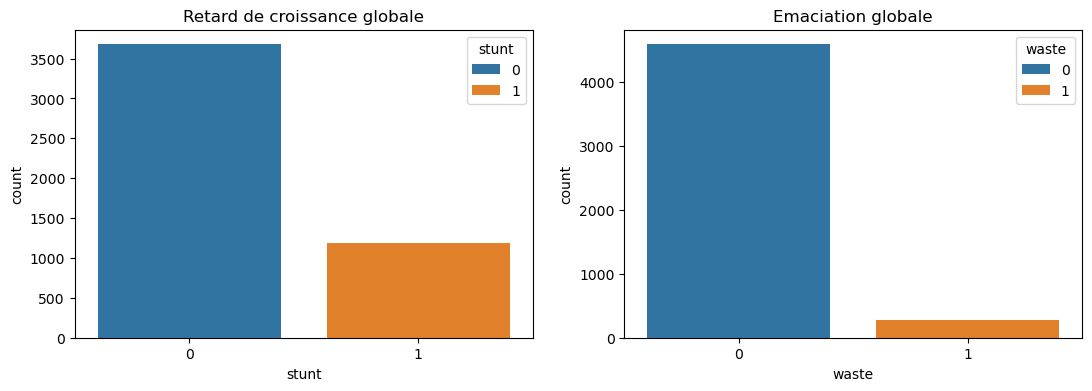

In [9]:
# Emaciation
nb_waste = pd.DataFrame({
    'nombre' : df['waste'].value_counts(),
    'proportion' : round(df['waste'].value_counts(normalize=True)*100, 2)
})

# Retard de croissance
nb_stunt = pd.DataFrame({
    'nombre' : df['stunt'].value_counts(),
    'proportion' : round(df['stunt'].value_counts(normalize=True)*100, 2)
})

# Affichage
print('\n')
print(f"{30*'-'} Wasting(Emaciation) {30*'-'}")
print(nb_waste)
print('\n')

print(f"{25*'-'} Stunting(Retard de croissance) {25*'-'}")
print(nb_stunt)
print('\n')

# Visualisation
plt.figure(figsize=(13,4))

plt.subplot(1,2,1)
sns.countplot(x='stunt', data=df, hue='stunt')
plt.title("Retard de croissance globale")

plt.subplot(1,2,2)
sns.countplot(x='waste', data=df, hue='waste')
plt.title("Emaciation globale")



plt.show()



Explication : 


1 ------------------------------ MOYEN
2 ------------------------------ ELEVEE


------------------------------ Atteints Wasting(Emaciation) ------------------------------
              nombre  proportion
waste_niveau                    
1                222       79.57
2                 57       20.43


------------------------- Atteints Stunting(Retard de croissance) -------------------------
              nombre  proportion
stunt_niveau                    
1                834       70.32
2                352       29.68




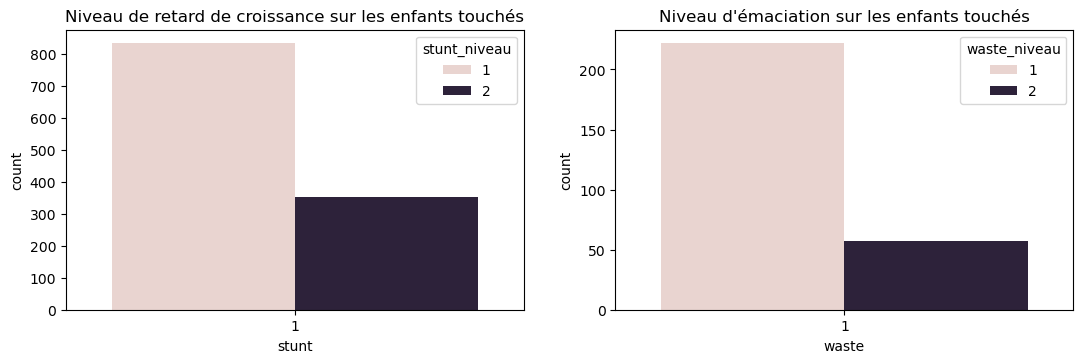

In [10]:
# Conditions
stunt = df.loc[(df['stunt'] == 1)]
waste = df.loc[(df['waste'] == 1)]


# Emaciation sur les enfants touchés
nb_waste_1 = pd.DataFrame({
    'nombre' : waste['waste_niveau'].value_counts(),
    'proportion' : round(waste['waste_niveau'].value_counts(normalize=True)*100, 2)
})

# Retard de croissance sur les enfants touchés
nb_stunt_1 = pd.DataFrame({
    'nombre' : stunt['stunt_niveau'].value_counts(),
    'proportion' : round(stunt['stunt_niveau'].value_counts(normalize=True)*100, 2)
})


# Affichage
print('\n')

print("Explication : ")
print('\n')
print(f"1 {30*'-'} MOYEN")
print(f"2 {30*'-'} ELEVEE")
print('\n')

print(f"{30*'-'} Atteints Wasting(Emaciation) {30*'-'}")
print(nb_waste_1)
print('\n')

print(f"{25*'-'} Atteints Stunting(Retard de croissance) {25*'-'}")
print(nb_stunt_1)
print('\n')

# Visualisation
plt.figure(figsize=(13,8))

plt.subplot(2,2,1)
sns.countplot(x='stunt', data=stunt, hue='stunt_niveau')
plt.title("Niveau de retard de croissance sur les enfants touchés")


plt.subplot(2,2,2)
sns.countplot(x='waste', data=waste, hue='waste_niveau')
plt.title("Niveau d'émaciation sur les enfants touchés")

plt.show()

**lecture rapide** :
 -  `Le nombre d'enfants en emaciation(wasting) dans la population correspond à ~5,74%` : implique une **classe rare à prendre en compte sur les métriques**.
 -  `Le nombre d'enfants en retard de croissance(stunting) dans la population correspond à ~24,8%`

### Croisement Stunting & Wasting

In [11]:
pd.crosstab(df['waste'], df['stunt'], normalize='index')

stunt,0,1
waste,,
0,0.762268,0.237732
1,0.655914,0.344086


**Lecture rapide** :
 - Dans la population des personnes non atteints de wasting (emaciation) `23,77% est atteint de stunting(reatrd de croissance)[1]`
 - Dans la population des personnes atteints de wasting (emaciation) `34,44% est atteint de stunting(reatrd de croissance)[1]`

### Visualisation des croisements

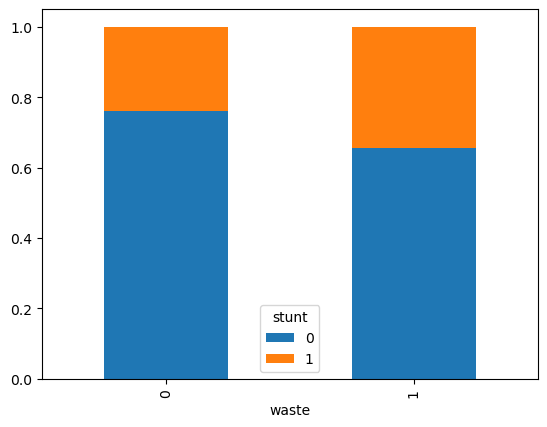

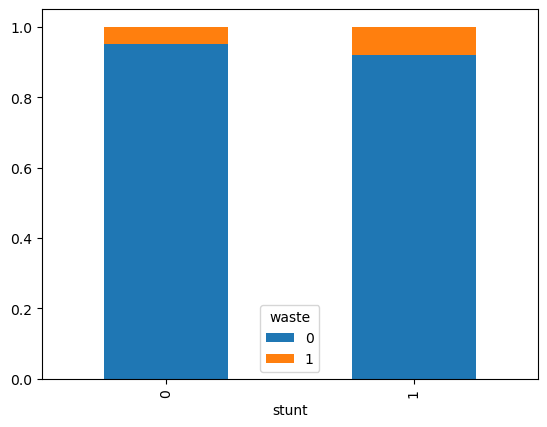

In [12]:
pd.crosstab(df['waste'], df['stunt'], normalize='index').plot(kind='bar',stacked=True)

pd.crosstab(df['stunt'], df['waste'], normalize='index').plot(kind='bar',stacked=True)

plt.show()

**Choix** : **`Les deux cibles ont peu de chevauchements donc la mise en place de deux modeles d'apprentissage distincts est nécessaire`**.

# Distinction des prévalences

# Analyse continue

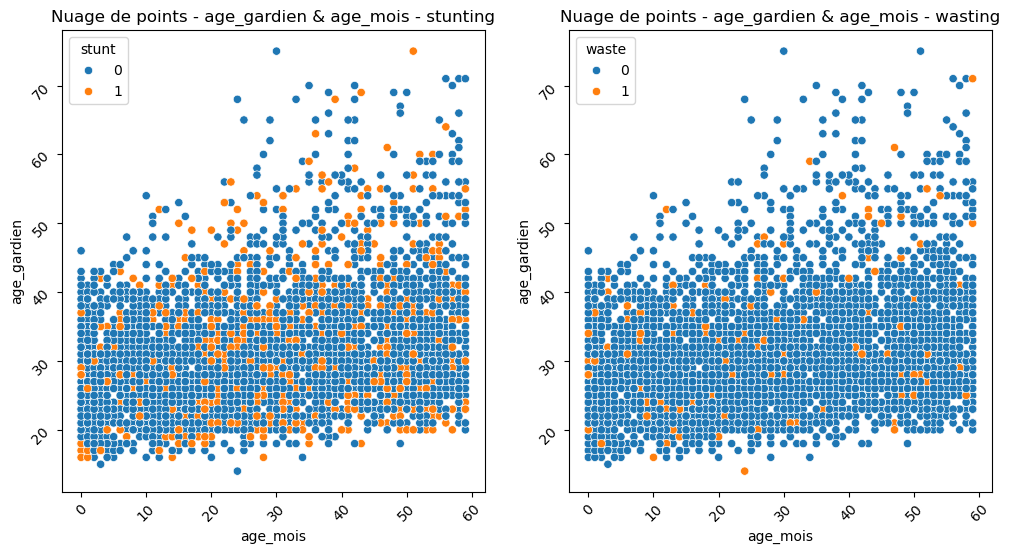

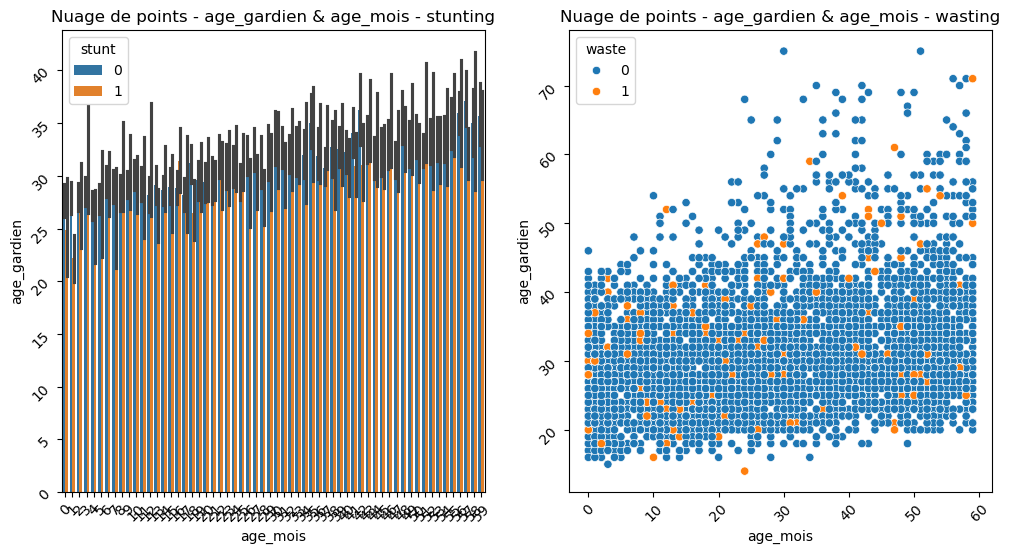

In [13]:
plt.figure(figsize=(12,6))

# Stunting
plt.subplot(1,2,1)
sns.scatterplot(y='age_gardien', x='age_mois', data=df, hue='stunt')
plt.ylabel("age_gardien")
plt.xlabel('age_mois')
plt.xticks(rotation = 45 )
plt.yticks(rotation = 45 )
plt.title("Nuage de points - age_gardien & age_mois - stunting")



# Wasting
plt.subplot(1,2,2)
sns.scatterplot(y='age_gardien', x='age_mois', data=df, hue='waste')
plt.ylabel("age_gardien")
plt.xlabel('age_mois')
plt.xticks(rotation = 45 )
plt.yticks(rotation = 45 )
plt.title("Nuage de points - age_gardien & age_mois - wasting")


plt.figure(figsize=(12,6))

# Stunting
plt.subplot(1,2,1)
sns.barplot(y='age_gardien', x='age_mois', data=df, hue='stunt')
plt.ylabel("age_gardien")
plt.xlabel('age_mois')
plt.xticks(rotation = 45 )
plt.yticks(rotation = 45 )
plt.title("Nuage de points - age_gardien & age_mois - stunting")



# Wasting
plt.subplot(1,2,2)
sns.scatterplot(y='age_gardien', x='age_mois', data=df, hue='waste')
plt.ylabel("age_gardien")
plt.xlabel('age_mois')
plt.xticks(rotation = 45 )
plt.yticks(rotation = 45 )
plt.title("Nuage de points - age_gardien & age_mois - wasting")


plt.show()

<Axes: xlabel='taille_menage', ylabel='grappe'>

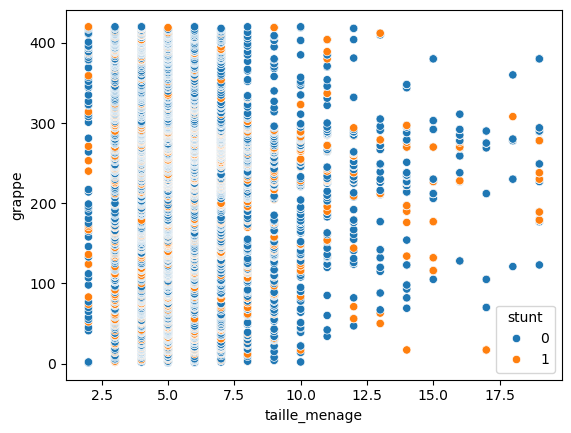

In [14]:
sns.scatterplot(x = 'taille_menage', y='grappe', data=df, hue='stunt')

<Axes: xlabel='grappe', ylabel='Count'>

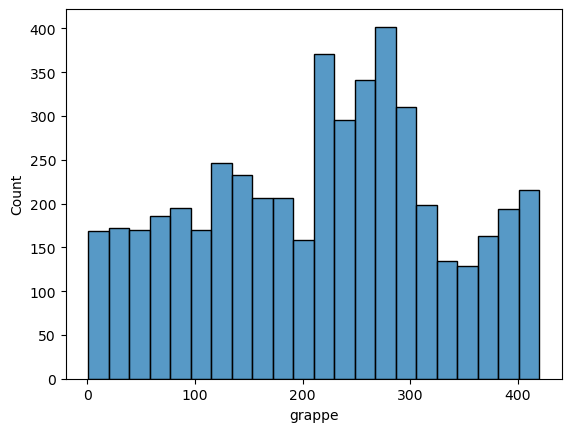

In [15]:
sns.histplot(x='grappe', data=df)

# Repartition du stunting par age (mois & gardien)

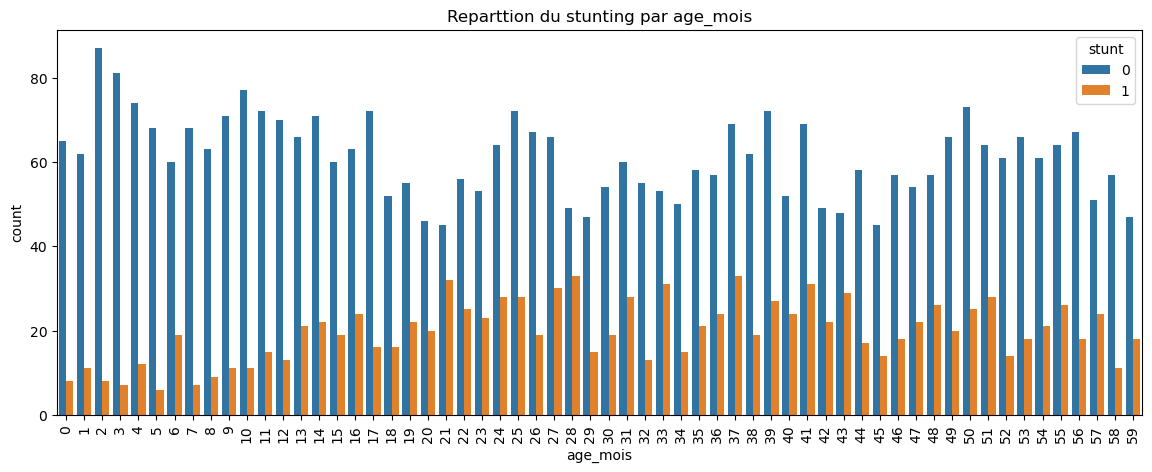

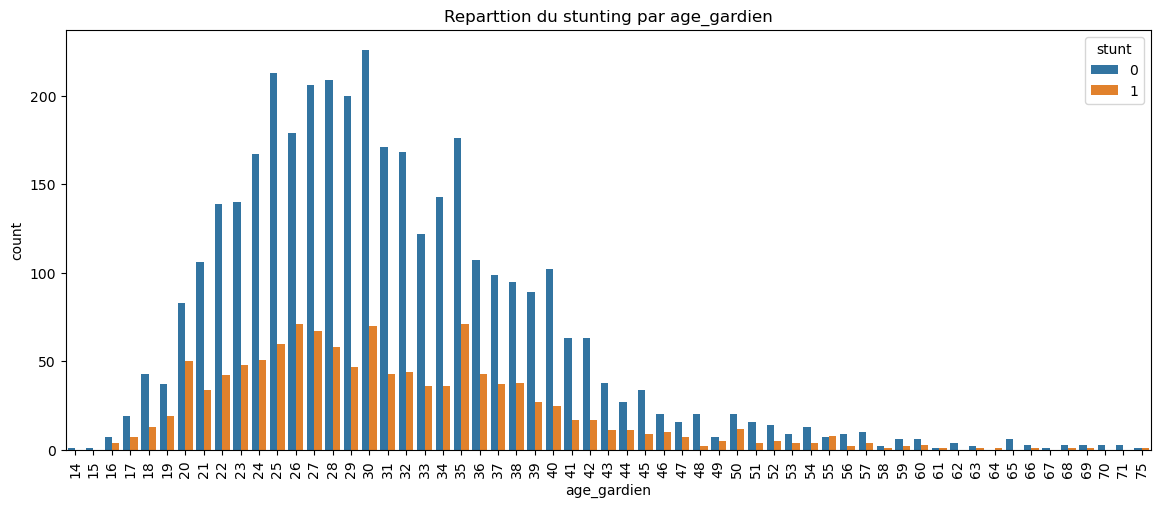

In [34]:
plt.figure(figsize=(14,5))

#plt.subplot(1,1,1)
sns.countplot(x='age_mois', data=df, hue='stunt')
plt.xticks(rotation=90)
plt.title("Reparttion du stunting par age_mois")


plt.figure(figsize=(14,12))
plt.subplot(2,1,1)
sns.countplot(x='age_gardien', data=df, hue='stunt')
plt.xticks(rotation=90)
plt.title("Reparttion du stunting par age_gardien")


plt.show()

# Repartition du wasting par age (mois & gardien)

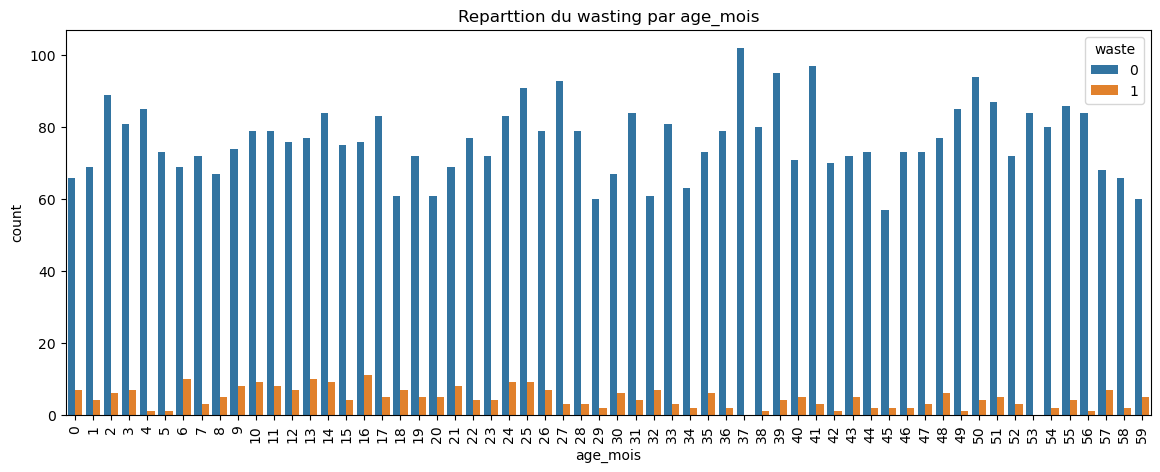

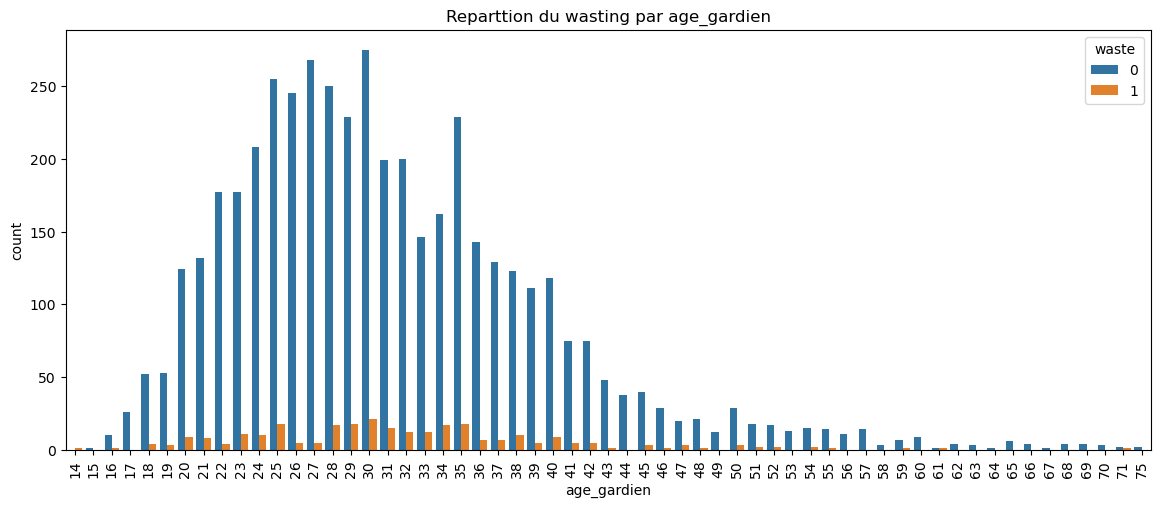

In [35]:
plt.figure(figsize=(14,5))

#plt.subplot(1,1,1)
sns.countplot(x='age_mois', data=df, hue='waste')
plt.xticks(rotation=90)
plt.title("Reparttion du wasting par age_mois")


plt.figure(figsize=(14,12))
plt.subplot(2,1,1)
sns.countplot(x='age_gardien', data=df, hue='waste')
plt.xticks(rotation=90)
plt.title("Reparttion du wasting par age_gardien")


plt.show()

# Distribution des variables

In [18]:
print(f"Differentes colonnes : {df.columns}")

Differentes colonnes : Index(['grappe', 'menage', 'id_menage', 'ligne_enfant', 'stunt', 'waste',
       'stunt_niveau', 'waste_niveau', 'haz', 'whz', 'age_mois', 'region',
       'edu_mere', 'electricite', 'cuisiniere', 'toilettes', 'sexe_f',
       'acte_naissance', 'eau_amelioree', 'animaux', 'age_gardien',
       'taille_menage', 'lavage_mains', 'telephone', 'poids_enfant', 'milieu',
       'quintile_richesse', 'ethnie'],
      dtype='object')


### Variables numériques

<Axes: xlabel='age_mois', ylabel='Count'>

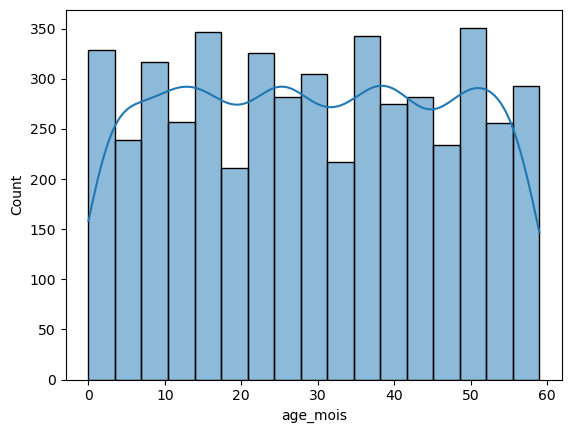

In [19]:
sns.histplot(x='age_mois', data=df, kde=True)

<Axes: xlabel='grappe', ylabel='Count'>

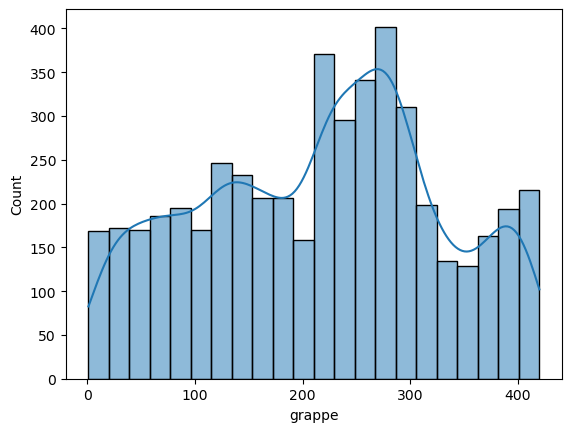

In [20]:
sns.histplot(x='grappe', data=df, kde=True)

### Variables catégorielles

# Prevalence de chaque cible selon chaque variables

# Etude de la courbe de l'age

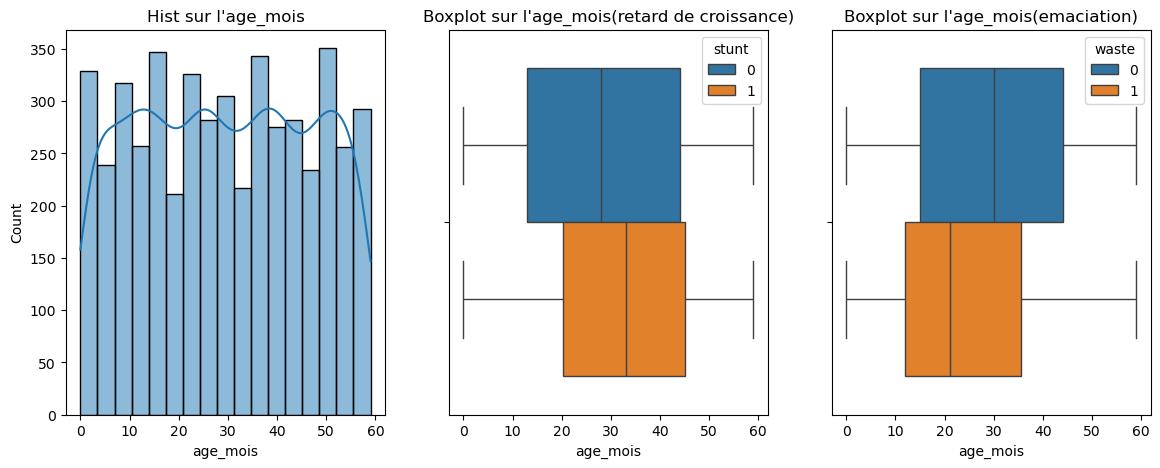

In [21]:
plt.figure(figsize=(14,5))

plt.subplot(1,3,1)
sns.histplot(df['age_mois'], kde=True)
plt.title("Hist sur l'age_mois")

plt.subplot(1,3,2)
sns.boxplot(x='age_mois', data=df, hue='stunt')
plt.title("Boxplot sur l'age_mois(retard de croissance)")

plt.subplot(1,3,3)
sns.boxplot(x='age_mois', data=df, hue='waste')
plt.title("Boxplot sur l'age_mois(emaciation)")

plt.show()

### Etude variables numériques

#### Age du gardien

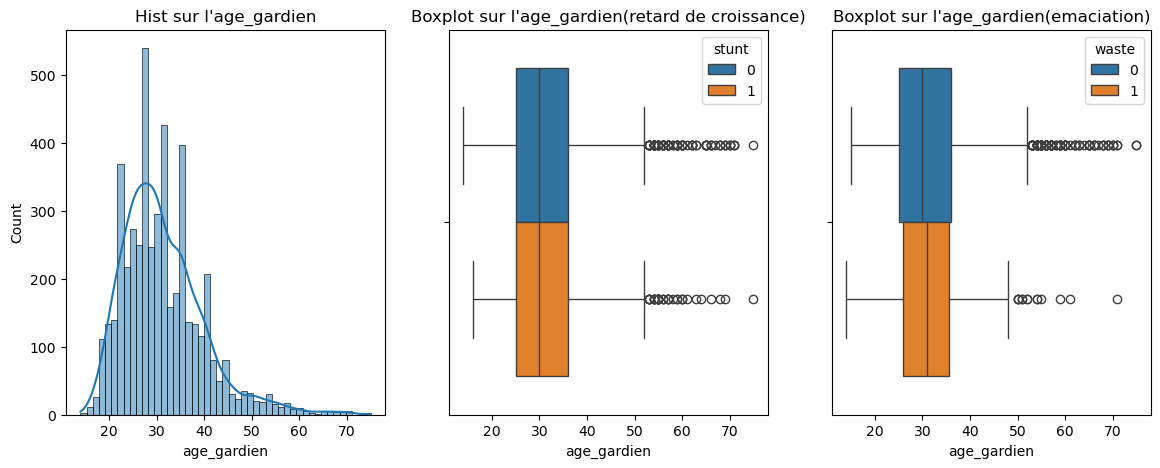

In [22]:
plt.figure(figsize=(14,5))

plt.subplot(1,3,1)
sns.histplot(df['age_gardien'], kde=True)
plt.title("Hist sur l'age_gardien")

plt.subplot(1,3,2)
sns.boxplot(x='age_gardien', data=df, hue='stunt')
plt.title("Boxplot sur l'age_gardien(retard de croissance)")

plt.subplot(1,3,3)
sns.boxplot(x='age_gardien', data=df, hue='waste')
plt.title("Boxplot sur l'age_gardien(emaciation)")

plt.show()

#### Taille du ménage

# Liens entre variables d'entrées

## Corrélation φK entre les variables d'entrée

**Quoi.** φK (prononcé "phi-K") mesure la force du lien entre deux variables, **quel que soit leur type** : numérique, texte ou 0/1. Pour chaque paire de variables d'entrée, il donne un chiffre entre 0 et 1. Le tout est affiché dans une carte de chaleur (*heatmap*).

**Pourquoi φK plutôt qu'une corrélation classique (Pearson).**
- Pearson ne marche que sur des variables numériques et ne voit que les liens en ligne droite.
- Ici, plusieurs variables sont du texte (région, type de cuisinière, toilettes...). φK les compare avec les numériques dans la même matrice.
- φK détecte aussi les liens **non linéaires** (par exemple un effet qui monte puis redescend avec l'âge).

**Comment φK fonctionne, en bref.** Les variables numériques sont découpées en classes. On construit ensuite, pour chaque paire, un tableau croisé (par exemple région × type de cuisinière). On mesure à quel point ce tableau s'écarte de ce qu'on verrait si les deux variables étaient indépendantes. Plus l'écart est grand, plus φK est proche de 1.

**Utilité ici.** Repérer les **variables redondantes** parmi les entrées d'un même modèle. Deux variables qui disent presque la même chose n'apportent pas plus d'information à deux qu'à une seule. Elles compliquent le modèle et rendent ses coefficients plus difficiles à interpréter.

### Comment lire la heatmap

| φK entre deux variables | Ce que ça veut dire |
|---|---|
| **proche de 0** (< 0,2) | Les variables sont **quasi indépendantes** : savoir l'une n'apprend presque rien sur l'autre |
| **autour de 0,3 à 0,5** | Lien modéré, à surveiller sans s'inquiéter |
| **autour de 0,6 et plus** | Lien fort : les deux variables sont probablement **redondantes** |
| **proche de 1** | Presque la même information écrite de deux façons |

(Ces seuils sont des repères habituels, pas des règles strictes.)

**Un φK proche de 0 entre deux variables d'entrée est une bonne nouvelle.** Cela veut dire que chacune apporte une information qui lui est propre : pas de redondance. Ce n'est **pas** un signe qu'elles sont inutiles.

### Ce que φK entre entrées ne dit pas

- **Il ne dit rien sur l'utilité d'une variable pour prédire la cible.** Une variable peut être très peu liée aux autres entrées et quand même très liée à `stunt` ou `waste` (excellent), ou n'avoir aucun lien avec la cible (inutile). Pour juger l'utilité, il faut regarder φK **entre chaque entrée et la cible**, pas entre entrées.
- **Il ne donne pas le sens du lien.** φK est toujours positif : il dit que les variables sont liées, pas si l'une augmente quand l'autre diminue.
- **Il ne prouve aucune cause.** Il décrit seulement des variables qui varient ensemble dans l'échantillon.

### Règle de décision pour ce projet

1. Une paire d'entrées avec φK élevé (≥ 0,6) est candidate à la simplification : on en garde une seule, ou on les regroupe.
2. Avant de supprimer une des deux, on compare leur lien avec la cible et on garde celle qui est la plus liée à la cible. Une variable plus facile à recueillir ou à comprendre dans l'outil final est aussi un bon critère.
3. Les paires à φK faible sont conservées sans souci : ce sont des informations complémentaires.
4. Cette analyse est **exploratoire**. La décision finale se confirme avec les performances du modèle, sur des données découpées par grappe.

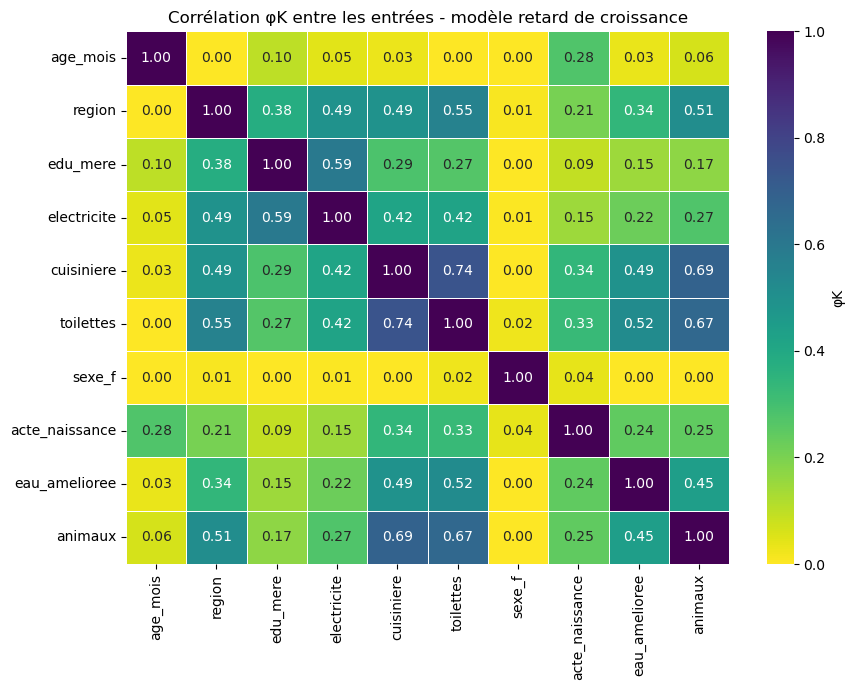

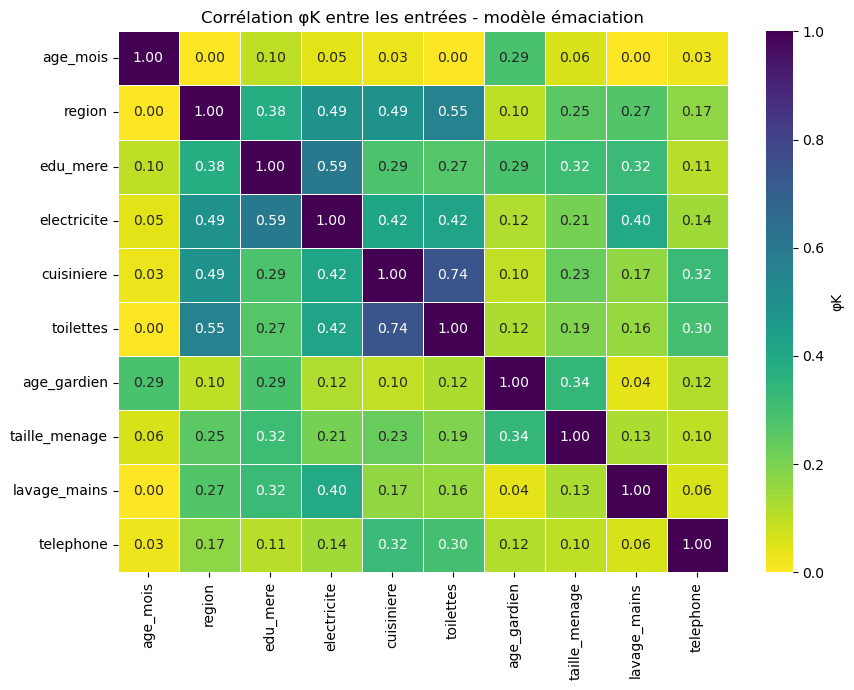

In [23]:
import phik                      # pip install phik

# Variables d'entrée par modèle
COMMUNES   = ["age_mois", "region", "edu_mere", "electricite", "cuisiniere", "toilettes"]
RETARD     = COMMUNES + ["sexe_f", "acte_naissance", "eau_amelioree", "animaux"]
EMACIATION = COMMUNES + ["age_gardien", "taille_menage", "lavage_mains", "telephone"]

# Seules vraies variables continues (phik les découpe en classes).
# Les objets et les 0/1 sont traités comme catégoriels.
CONTINUES = ["age_mois", "age_gardien", "taille_menage"]

def matrice_phik(colonnes):
    X = df[colonnes].copy()
    for c in X.select_dtypes("Int8").columns:        # pd.NA -> NaN
        X[c] = X[c].astype("float64")
    return X.phik_matrix(interval_cols=[c for c in CONTINUES if c in colonnes])

def tracer(matrice, titre):
    plt.figure(figsize=(9, 7))
    sns.heatmap(matrice, annot=True, fmt=".2f", vmin=0, vmax=1,
                cmap="viridis_r", linewidths=.5, cbar_kws={"label": "φK"})
    plt.title(titre)
    plt.tight_layout()
    plt.show()

phik_retard     = matrice_phik(RETARD)
phik_emaciation = matrice_phik(EMACIATION)

tracer(phik_retard,     "Corrélation φK entre les entrées - modèle retard de croissance")
tracer(phik_emaciation, "Corrélation φK entre les entrées - modèle émaciation")

# Liens entre variables et la cible

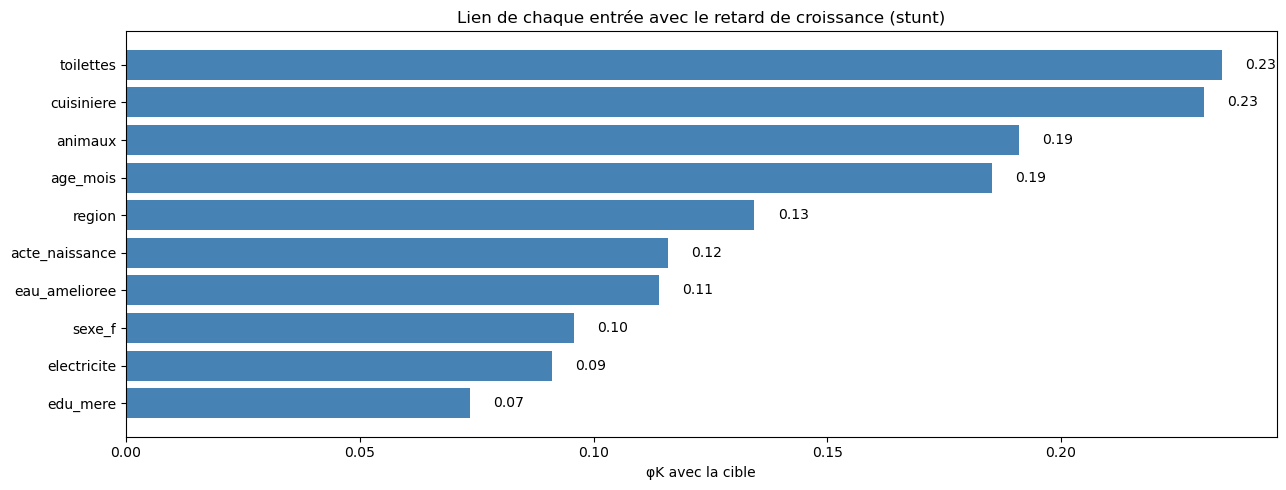

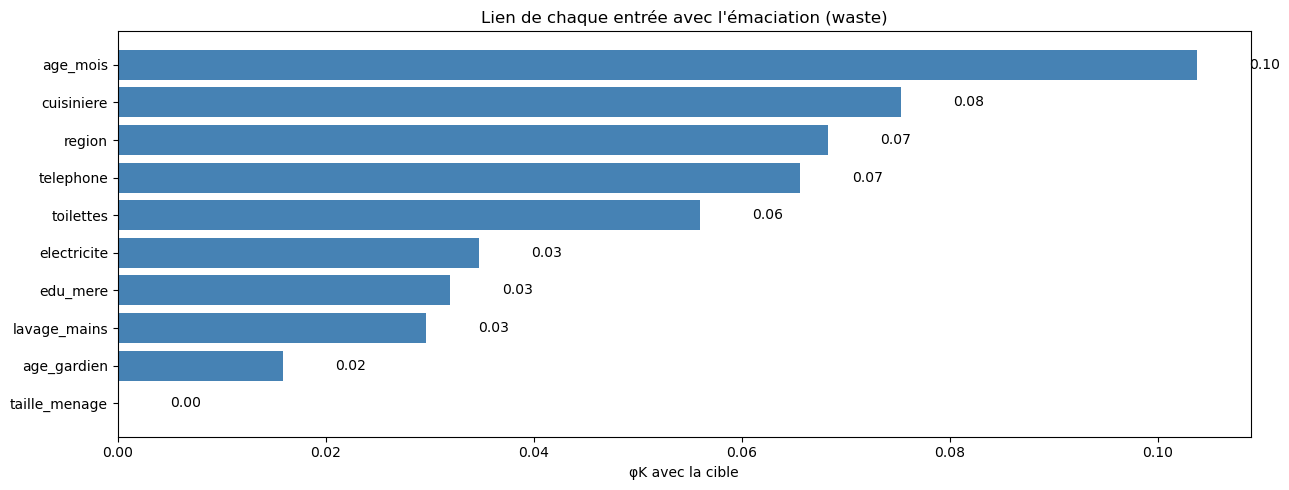

In [36]:
def phik_avec_cible(entrees, cible):
    # matrice_phik() accepte n'importe quelle liste de colonnes, cible comprise
    m = matrice_phik(entrees + [cible])
    return m[cible].drop(cible).sort_values()          # du plus faible au plus fort

def tracer_cible(serie, titre):
    plt.figure(figsize=(13, 5))
    plt.barh(serie.index, serie.values, color="steelblue")
    for i, v in enumerate(serie.values):
        plt.text(v + 0.005, i, f"{v:.2f}", va="center")
    plt.xlabel("φK avec la cible")
    plt.title(titre)
    plt.tight_layout()
    plt.show()

phik_stunt = phik_avec_cible(RETARD, "stunt")
phik_waste = phik_avec_cible(EMACIATION, "waste")

tracer_cible(phik_stunt, "Lien de chaque entrée avec le retard de croissance (stunt)")
tracer_cible(phik_waste, "Lien de chaque entrée avec l'émaciation (waste)")

# Separation fichiers parquet

In [25]:
ENTREES_COMMUNES = ["age_mois", "region", "edu_mere", "electricite", "cuisiniere", "toilettes"]

IDENTIFIANTS = ["grappe", "menage", "id_menage", "ligne_enfant"]


ENTREES_RETARD = ["sexe_f", "acte_naissance", "eau_amelioree", "animaux"]
SORTIE_RETARD = ['stunt']

ENTREES_EMACIATION = ["age_gardien", "taille_menage", "lavage_mains", "telephone"]
SORTIE_EMACIATION = ['waste']

VARIABLES_STUNTING = ENTREES_COMMUNES + ENTREES_RETARD + SORTIE_RETARD + IDENTIFIANTS
VARIABLES_WASTING = ENTREES_COMMUNES + ENTREES_EMACIATION + SORTIE_EMACIATION + IDENTIFIANTS

In [26]:
wasting = df[VARIABLES_WASTING]
wasting.columns

Index(['age_mois', 'region', 'edu_mere', 'electricite', 'cuisiniere',
       'toilettes', 'age_gardien', 'taille_menage', 'lavage_mains',
       'telephone', 'waste', 'grappe', 'menage', 'id_menage', 'ligne_enfant'],
      dtype='object')

In [27]:
stunting = df[VARIABLES_STUNTING]
stunting.columns

Index(['age_mois', 'region', 'edu_mere', 'electricite', 'cuisiniere',
       'toilettes', 'sexe_f', 'acte_naissance', 'eau_amelioree', 'animaux',
       'stunt', 'grappe', 'menage', 'id_menage', 'ligne_enfant'],
      dtype='object')

# Fichier parquet de modélisation

In [28]:
RACINE = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
DOSSIER_BRUT = RACINE / "data" / "raw"
DOSSIER_PROPRE = RACINE / "data" / "clean"
DOSSIER_PROPRE.mkdir(parents=True, exist_ok=True)

chemin_wasting = DOSSIER_PROPRE / "model_wasting.parquet"
wasting.to_parquet(chemin_wasting, index=False)

chemin_stunting = DOSSIER_PROPRE / "model_stunting.parquet"
stunting.to_parquet(chemin_stunting, index=False)